# 45. Event-weighted pre-onset AUC: is the 24-hour M0 advantage a product of minute weighting?

In notebook 41, the interval of the 24-hour pre-onset AUC difference (GBM − M0 = −0.090) included 0 once I removed two fast declines (211 and 190 pre-onset minutes; 401 of 3,971 pre-onset minutes in total). The per-minute pre-onset AUC equals exactly the average of per-event pre-onset AUCs weighted by each event's number of pre-onset minutes (with the same negatives), so events with many pre-onset minutes dominate. Here I compute the pre-onset AUC from the same minutes, scores and negatives with equal weight per event and test whether the M0 advantage remains.

- Definitions: for each event e with pre-onset minutes, AUC_e = Pr{s(pre-onset minute of e) > s(negative minute)} (+½ for ties), and the event-weighted pre-onset AUC is the simple mean of AUC_e over those events. The per-minute pre-onset AUC equals Σ_e (n_e / Σn) AUC_e, with n_e the number of pre-onset minutes of event e. The within-regime version counts only pairs in the same RV decile. Event weighting is not the "more correct" measure: per-minute weighting gives equal weight to each minute and event weighting to each event, the two are different estimands, and their difference measures sensitivity to the weighting.
- Inference: all differences are GBM − M0 with the negatives unchanged. For intervals I use the same two schemes as notebook 41: 2,000 draws of a 7-day block bootstrap (an event's weight is the mean multiplicity of its pre-onset minutes) and 2,000 draws of an event bootstrap (I resample all events of the definition with replacement, keep the negatives fixed and weight each event by the number of times it is drawn).
- Inputs: the spot cache (`cache/`), the notebook 02 event catalog, the frozen notebook 16 models (`methods_definitions_v1`), and the saved results that I reproduce from notebook 22 (`2_per_minute_by_window.csv`), notebook 33 (`1_decomposition_point.csv`) and notebook 41 (`41_SPEC.json`, `2_subset_intervals.csv`).
- Status: exploratory and post hoc; I designed this analysis after seeing the notebook 41 results, limit it to the development period and leave the preregistration plans (OSF TB245, BKJUQ) unchanged.
- Results folder: `event_weighted_preonset_v1`; the outputs contain only times, counts, AUCs and intervals, no prices.

I wrote the reading rules R1–R5 (R1, the main reading, concerns the 24-hour event-weighted difference) before seeing the results and recorded them in `45_SPEC.json`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
import joblib, re

OUT = SPOT_BASE / 'event_weighted_preonset_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
M22 = SPOT_BASE / 'peak_window_v1'
M33 = SPOT_BASE / 'shapley_decomposition_v1'
M41 = SPOT_BASE / 'complement_fragility_v1'
DNAME, DCL = '4pct', 0.04
H_REF, H_24 = 240, 1440; H_LIST = [H_REF, H_24]
PSCORES = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich', 'B0_RV24h_baseline']        # common-minute set of notebooks 29, 32, 33, 36, 41
A_NAME, B_NAME = 'M3_GBM_rich', 'M0_VF_logit'                                              # every difference is A - B (GBM - M0)
SEED = 20261145
N_BLOCK = 2000; N_EVENT = 2000; BLOCK_DAYS = 7
MIN_PRE_EVENTS = 5; MIN_FINITE = 0.95
MOCK_BYPASS = ()                                     # empty on Colab; only the synthetic test run lists guard names here, and every bypass is printed and recorded
EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS
GUARDS = []


def guard(name, ok, msg):
    """Record a guard; raise RuntimeError('GUARD FAIL: ...') unless it holds. A guard listed in MOCK_BYPASS (synthetic test run only) is reported, not raised."""
    ok = bool(ok); byp = (not ok) and (name in MOCK_BYPASS)
    GUARDS.append(dict(guard=name, passed=ok, bypassed_in_mock=byp, detail=str(msg)))
    if ok:
        return True
    if byp:
        print(f'Guard "{name}" bypassed: {msg} (synthetic test run only)', flush=True)
        return False
    raise RuntimeError(f'GUARD FAIL: {msg}')


for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', M22 / '2_per_minute_by_window.csv', M33 / '1_decomposition_point.csv',
           M41 / '41_SPEC.json', M41 / '2_subset_intervals.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 16, 22, 33 and 41 are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')
SPEC41 = json.loads((M41 / '41_SPEC.json').read_text())
_mb = re.match(r'(\d+) draws', SPEC41['intervals']['block']); _me = re.match(r'(\d+) draws', SPEC41['intervals']['event_a'])
guard('spec41_parsed', _mb is not None and _me is not None, 'draw counts of notebook 41 not recognised in 41_SPEC.json')
SEED41, N_BLOCK41, N_EVENT41 = int(SPEC41['seed']), int(_mb.group(1)), int(_me.group(1))

SPEC = {'title': 'Event-weighted pre-onset AUC: is the 24-hour M0 pre-onset lead a product of minute weighting? (exploratory, post hoc; development sample)',
        'inputs': 'spot cache, notebook-2 catalog, notebook-16 frozen models; stored results of notebooks 22, 33 and 41 for guards; holdouts and the prospective folder not read',
        'minutes': 'notebook-33 common minutes (valid, finite M0, M1, GBM, B0 scores, RV decile assigned, evaluation period)',
        'estimands': {'per_event': 'AUC_e = Pr{s(pre-onset minute of event e) > s(negative minute)} + 1/2 Pr{tie}, negatives common to all events',
                      'minute_weighted': 'sum_e n_e AUC_e / sum_e n_e (n_e pre-onset minutes of e) = the per-minute pre-onset AUC of Tables 3 and 6',
                      'event_weighted': 'mean of AUC_e over events with at least one pre-onset minute',
                      'within_regime': 'same with pairs counted only inside RV deciles (per-event within-regime AUC, then the mean)'},
        'intervals': {'block': f'{N_BLOCK} draws of {BLOCK_DAYS}-day blocks (seed {SEED} + 1), shared by both systems; event weight = mean block multiplicity of its pre-onset minutes',
                      'event_a': f'{N_EVENT} draws: all events of the definition resampled with replacement (seed {SEED} + 100 + H), negatives fixed; event weight = multiplicity',
                      'level': '95% percentile intervals over finite draws'},
        'readings': {'R1': 'H=1440 GBM - M0 event-weighted pre-onset AUC: block and event intervals both below zero -> M0 lead holds with equal event weights; both above -> GBM ahead with equal event weights; '
                           'otherwise not distinguishable with equal event weights (the per-minute lead rests on weighting by pre-onset minutes)',
                     'R2': 'H=1440: number of events with pre-onset minutes in which M0 AUC_e exceeds GBM AUC_e (descriptive; events are not independent); five largest contributions to minute-weighted minus event-weighted difference',
                     'R3': 'H=1440 event-weighted within-regime pre-onset difference: rule of R1 (secondary)',
                     'R4': 'H=240: M0 event-weighted pre-onset AUC and GBM - M0 event-weighted difference (descriptive)',
                     'R5': 'H=1440: leave-one-event-out range of the event-weighted difference (descriptive)',
                     'undetermined': f'an interval with a non-finite end or fewer than {MIN_FINITE:.0%} finite draws is undetermined; fewer than {MIN_PRE_EVENTS} events with pre-onset minutes -> not interpretable'},
        'guards': 'notebook-22 per-minute AUCs; notebook-33 GBM - M0 points; unit calculator with unit weights equals make_parts/stats_from; minute-weighted mean of per-event AUCs equals the per-minute AUC; '
                  'notebook-41 all-event pre-onset block and event intervals reproduced with the notebook-41 draws',
        'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256'], 'designed_after': 'notebook 41 (greedy deletion path) results were known',
        'status': 'exploratory; post hoc; development sample only; no confirmatory plan changed'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '45_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'45_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest(); (OUT / '45_SPEC.sha256').write_text(f'{SPEC_SHA}  45_SPEC.json\n')
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16], '| skipped checks:', MOCK_BYPASS if MOCK_BYPASS else 'none')

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/event_weighted_preonset_v1 | spec sha256 94cf5cfa241d5cfe | skipped checks: none


## 0. Reproduction of scores, labels, blocks and deciles

I reproduce them with the same code as section 0 of notebook 41.

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < DCL / 4)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1
TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']


def catalog_H(H):
    E_ = price_only_catalog(close, volume, px.index, H=H, decline=DCL)
    for c_ in TCOLS:
        E_[c_] = pd.to_datetime(E_[c_], utc=True)
    return E_.sort_values('breach_utc').reset_index(drop=True)


def in_decline_mask(E_, y_):
    br = E_.breach_utc.astype('int64').to_numpy(); on = E_.onset_1pct_utc.astype('int64').to_numpy()
    pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left'); ok = pos < len(br)
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= on[pos[ok]]
    return inn & (y_ == 1)


def event_of_minute(E_, y_):
    br = E_.breach_utc.astype('int64').to_numpy(); pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left')
    out = np.full(len(T), -1, np.int64); ok = (y_ == 1) & (pos < len(br)); out[ok] = pos[ok]
    return out


E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
CAT = {H: catalog_H(H) for H in H_LIST}
guard('catalog_nb2', len(CAT[H_REF]) == len(E_ref) and all(np.array_equal(CAT[H_REF][c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS),
      'H=240 catalog differs from the notebook-2 catalog')
EV = {H: events_between(CAT[H], EVAL_START, EVAL_END).reset_index(drop=True) for H in H_LIST}
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = train_mask(T, VALID) & np.isfinite(Xl).all(axis=1)
cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
m0 = new_logit().fit(Xl[okl], label_from_catalog(T, CAT[H_REF])[okl])
guard('m0_refit_nb16', np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9),
      'M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
guard('gbm_sha_nb16', sha256_file(mp) == cfg3['model_sha256'], 'notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(mp)
IDX = np.flatnonzero(EVM); S = {}
s = np.full(len(T), np.nan); okp = EVM & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[IDX] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
S['B0_RV24h_baseline'] = np.where(VALID, RV, np.nan)
del Xl, F, sg, g3

PM22 = pd.read_csv(M22 / '2_per_minute_by_window.csv'); ONES = np.ones(N_WEEKS); LAB = {}; EVOF = {}
for H in H_LIST:
    yH = label_from_catalog(T, CAT[H]); innH = in_decline_mask(CAT[H], yH)
    LAB[H] = np.where(yH == 1, np.where(innH, 2, 1), 0).astype(np.int64); EVOF[H] = event_of_minute(CAT[H], yH)
    for sname in PSCORES:
        m = EVM & np.isfinite(S[sname]) & (DEC >= 0)
        pt = stats_from(make_parts(S[sname][m], LAB[H][m], CALM[m], WEEK[m], DEC[m]), ONES)
        ref = PM22[(PM22.H == H) & (PM22.score == sname)]
        dmax = max(abs(pt[k] - float(ref.iloc[0][k])) for k in ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime']) if len(ref) == 1 else np.inf
        guard('per_minute_nb22', dmax <= 1e-9, f'per-minute point estimate differs from notebook 22 (H={H}, {sname}) by {dmax:.2e}')
MC = EVM & (DEC >= 0)
for sname in PSCORES:
    MC &= np.isfinite(S[sname])
PT33 = pd.read_csv(M33 / '1_decomposition_point.csv'); PT33 = PT33[(PT33.h1 == H_REF) & (PT33.h2 == H_24)].iloc[0]
Q0 = {}
for H, tag in ((H_REF, 'h1'), (H_24, 'h2')):
    ra = stats_from(make_parts(S[A_NAME][MC], LAB[H][MC], CALM[MC], WEEK[MC], DEC[MC]), ONES); rb = stats_from(make_parts(S[B_NAME][MC], LAB[H][MC], CALM[MC], WEEK[MC], DEC[MC]), ONES)
    Q0[H] = dict(pi=ra['share_in'], D=ra['auc_standard'] - rb['auc_standard'], dpre=ra['auc_pre'] - rb['auc_pre'], din=ra['auc_in'] - rb['auc_in'],
                 m0_pre=rb['auc_pre'], gbm_pre=ra['auc_pre'], dpre_wr=ra['auc_pre_within_regime'] - rb['auc_pre_within_regime'])
dmax = max(abs(Q0[H][k] - float(PT33[f'{k}_{tag}'])) for H, tag in ((H_REF, 'h1'), (H_24, 'h2')) for k in ['pi', 'dpre', 'din', 'D'])
guard('nb33_point', dmax <= 1e-9, f'GBM - M0 point differences differ from notebook 33 by {dmax:.2e}')
print(f'PASS: models verified; per-minute AUCs equal notebook 22; GBM - M0 points equal notebook 33 (24 h pre-onset {Q0[H_24]["dpre"]:+.4f}) ({time.time() - t_:.0f}s)')

PASS: models verified; per-minute AUCs equal notebook 22; GBM - M0 points equal notebook 33 (24 h pre-onset -0.0903) (134s)


## 1. Per-event AUCs from (event × 7-day block) units

I compute the per-event AUCs with the same calculator over (event × 7-day block) units as in notebook 41.

In [3]:
t_ = time.time()


def pair_counts(sp, gp, n_gp, sn, gn, n_gn):
    """notebook 36/41: C[k, l] = over positives in group k, the number of negatives in group l with a lower score (+0.5 per tie)."""
    C = np.zeros((n_gp, n_gn))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, gn)); sn = sn[o]; gn = gn[o]
    bounds = np.searchsorted(gn, np.arange(n_gn + 1), 'left')
    for l in range(n_gn):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(gp, weights=lo + 0.5 * (hi - lo), minlength=n_gp)
    return C


def unit_parts(H):
    """notebook 41: positives grouped by unit = (event, block) on the common minutes; negatives by block; within-regime counts by RV decile."""
    m = MC; code = LAB[H][m]; evc = EVOF[H][m]; wk = WEEK[m]; dec = DEC[m]
    pos = code > 0; neg = code == 0; pre = code == 1; inn = code == 2
    uni = np.unique(evc[pos]); n_ev = len(uni)
    key = np.full(len(code), -1, np.int64); key[pos] = np.searchsorted(uni, evc[pos]) * N_WEEKS + wk[pos]
    ukeys, uinv = np.unique(key[pos], return_inverse=True); n_u = len(ukeys)
    unit = np.full(len(code), -1, np.int64); unit[pos] = uinv
    cu = lambda k: np.bincount(unit[k], minlength=n_u).astype(float)
    U = dict(H=H, uni=uni, n_ev=n_ev, n_u=n_u, unit_ev=ukeys // N_WEEKS, unit_wk=ukeys % N_WEEKS, P_pre=cu(pre), P_in=cu(inn),
             N=np.bincount(wk[neg], minlength=N_WEEKS).astype(float),
             Pq_pre=np.array([cu(pre & (dec == q)) for q in range(10)]), Nq=np.array([np.bincount(wk[neg & (dec == q)], minlength=N_WEEKS) for q in range(10)]).astype(float))
    for sn in (A_NAME, B_NAME):
        s = S[sn][m]
        Cs = np.zeros((n_u, N_WEEKS))
        for q in range(10):
            kq = dec == q
            Cs += pair_counts(s[pre & kq], unit[pre & kq], n_u, s[neg & kq], wk[neg & kq], N_WEEKS)
        U[sn] = dict(C_pre=pair_counts(s[pre], unit[pre], n_u, s[neg], wk[neg], N_WEEKS), C_in=pair_counts(s[inn], unit[inn], n_u, s[neg], wk[neg], N_WEEKS), Cs_pre=Cs)
    U['EI'] = np.zeros((n_u, n_ev)); U['EI'][np.arange(n_u), U['unit_ev']] = 1.0           # unit -> event indicator
    U['e_P_pre'] = U['P_pre'] @ U['EI']
    return U


def _div(a, b):
    a = np.asarray(a, float); b = np.asarray(b, float)
    return np.divide(a, b, out=np.full(np.broadcast(a, b).shape, np.nan), where=b > 0)


def unit_stats(U, sn, A, Wm):
    """notebook 41: A (draws, units) positive weights; Wm (draws, blocks) negative weights -> per-minute AUCs over draws."""
    P = U[sn]; A = np.atleast_2d(A); Wm = np.atleast_2d(Wm)
    Wn = Wm @ U['N']; Mp = A @ U['P_pre']; Mi = A @ U['P_in']
    sp = ((A @ P['C_pre']) * Wm).sum(1); si = ((A @ P['C_in']) * Wm).sum(1)
    swr = ((A @ P['Cs_pre']) * Wm).sum(1); dwr = ((A @ U['Pq_pre'].T) * (Wm @ U['Nq'].T)).sum(1)
    return dict(auc_standard=_div(sp + si, (Mp + Mi) * Wn), auc_pre=_div(sp, Mp * Wn), auc_in=_div(si, Mi * Wn), share_in=_div(Mi, Mp + Mi),
                auc_pre_within_regime=_div(swr, dwr))


def event_stats(U, sn, A, Wm):
    """Per-event pre-onset AUCs and event weights for each draw.
    Returns auc_e, aucwr_e (draws, events) and v_e (draws, events) = mean multiplicity of the event's pre-onset minutes (0 if absent from the draw)."""
    P = U[sn]; A = np.atleast_2d(A); Wm = np.atleast_2d(Wm)
    Wn = Wm @ U['N']                                                          # (draws,)
    num = (A * (Wm @ P['C_pre'].T)) @ U['EI']                                 # sum over the event's units of A_u * (C_pre[u] . w)
    mass = (A * U['P_pre'][None, :]) @ U['EI']                                # weighted pre-onset minutes of each event
    numwr = (A * (Wm @ P['Cs_pre'].T)) @ U['EI']
    denwr = (A * ((Wm @ U['Nq'].T) @ U['Pq_pre'])) @ U['EI']                  # sum_u A_u sum_q Pq_pre[q,u] (w . Nq[q])
    auc_e = _div(num, mass * Wn[:, None]); aucwr_e = _div(numwr, denwr)
    v_e = _div(mass, np.broadcast_to(U['e_P_pre'][None, :], mass.shape)); v_e = np.where(np.isfinite(v_e), v_e, 0.0)
    return auc_e, aucwr_e, v_e, mass


def wmean(x, w):
    """Weighted mean over events with positive weight and finite value, per draw."""
    ok = np.isfinite(x) & (w > 0); w2 = np.where(ok, w, 0.0); x2 = np.where(ok, x, 0.0)
    return _div((w2 * x2).sum(1), w2.sum(1))


def ew_diff(U, A, Wm):
    """GBM - M0 event-weighted pre-onset and within-regime pre-onset AUC per draw, and the M0 / GBM levels."""
    out = {}
    for sn in (A_NAME, B_NAME):
        ae, awr, v, _ = event_stats(U, sn, A, Wm)
        out[sn] = dict(ew_pre=wmean(ae, v), ew_pre_wr=wmean(awr, v))
    return {k: out[A_NAME][k] - out[B_NAME][k] for k in ('ew_pre', 'ew_pre_wr')}, out


def interval(d):
    d = np.asarray(d, float); f = np.isfinite(d)
    lo, hi = (np.percentile(d[f], [2.5, 97.5]) if f.sum() else (np.nan, np.nan))
    return float(lo), float(hi), float(f.mean())


def zero_status(lo, hi, fin):
    if not (np.isfinite(lo) and np.isfinite(hi)) or fin < MIN_FINITE:
        return 'undetermined'
    return 'excludes' if (lo > 0 or hi < 0) else 'includes'


UP = {H: unit_parts(H) for H in H_LIST}
print('units:', {H: (UP[H]['n_ev'], UP[H]['n_u'], int((UP[H]['e_P_pre'] > 0).sum())) for H in H_LIST}, f'({time.time() - t_:.0f}s)')
GR = []
for H in H_LIST:
    U = UP[H]; A1 = ONES[U['unit_wk']][None, :]
    for sn in (A_NAME, B_NAME):
        m = MC
        ref = stats_from(make_parts(S[sn][m], LAB[H][m], CALM[m], WEEK[m], DEC[m]), ONES)
        got = unit_stats(U, sn, A1, ONES[None, :])
        d1 = max(abs(float(got[k][0]) - ref[k]) for k in ('auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime') if np.isfinite(ref[k]))
        guard('unit_ones_vs_make_parts', d1 <= 1e-9, f'unit calculator differs from make_parts at H={H} {sn} by {d1:.2e}')
        ae, awr, v, mass = event_stats(U, sn, A1, ONES[None, :])
        mw = wmean(ae, mass)[0]                                                # minute-weighted mean of per-event AUCs
        denwr_e = ((ONES @ U['Nq'].T) @ U['Pq_pre']) @ U['EI']
        mwr = wmean(awr, denwr_e[None, :])[0]                                  # within regime: weights = number of within-decile pairs of the event
        d2 = max(abs(mw - ref['auc_pre']), abs(mwr - ref['auc_pre_within_regime']))
        guard('minute_weighted_identity', d2 <= 1e-12, f'minute-weighted mean of per-event AUCs differs from the per-minute AUC at H={H} {sn} by {d2:.2e}')
        GR.append(dict(H=H, score=sn, unit_vs_make_parts=d1, identity=d2))
# ---- guard (iii): notebook-41 section-2 all-event pre-onset intervals with the notebook-41 draws
SI41 = pd.read_csv(M41 / '2_subset_intervals.csv')
_rb = np.random.default_rng(SEED41 + 1)
WB41 = np.array([np.bincount(_rb.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float) for _ in range(N_BLOCK41)])
for H in H_LIST:
    U = UP[H]; n_ev = U['n_ev']
    _re = np.random.default_rng(SEED41 + 100 + 10 * 0 + H)
    Mm41 = np.array([np.bincount(_re.integers(0, n_ev, n_ev), minlength=n_ev).astype(float) for _ in range(N_EVENT41)])
    for k in ('auc_pre', 'auc_pre_within_regime'):
        ra = unit_stats(U, A_NAME, WB41[:, U['unit_wk']], WB41); rb = unit_stats(U, B_NAME, WB41[:, U['unit_wk']], WB41)
        bl, bh, _ = interval(ra[k] - rb[k])
        ra = unit_stats(U, A_NAME, Mm41[:, U['unit_ev']], np.ones((N_EVENT41, N_WEEKS))); rb = unit_stats(U, B_NAME, Mm41[:, U['unit_ev']], np.ones((N_EVENT41, N_WEEKS)))
        al, ah, _ = interval(ra[k] - rb[k])
        ref = SI41[(SI41.H == H) & (SI41.subset == 'all') & (SI41.quantity == k)].iloc[0]
        d3 = max(abs(bl - ref.block_lo), abs(bh - ref.block_hi), abs(al - ref.event_a_lo), abs(ah - ref.event_a_hi))
        guard('intervals_nb41', d3 <= 1e-9, f'notebook-41 all-event {k} intervals at H={H} not reproduced ({d3:.2e})')
        GR.append(dict(H=H, score=f'GBM-M0 {k} (nb41 intervals)', unit_vs_make_parts=np.nan, identity=d3))
del WB41, Mm41
pd.DataFrame(GR).to_csv(OUT / '1_guards.csv', index=False)
print(f'PASS: unit calculator, minute-weighted identity and notebook-41 intervals reproduced ({time.time() - t_:.0f}s)')

units: {240: (83, 83, 83), 1440: (218, 218, 30)} (11s)
PASS: unit calculator, minute-weighted identity and notebook-41 intervals reproduced (31s)


## 2. Event-weighted pre-onset AUC and intervals

In [4]:
t_ = time.time()
rng_b = np.random.default_rng(SEED + 1)
WB = np.array([np.bincount(rng_b.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float) for _ in range(N_BLOCK)])
ROWS = []; PER_EVENT = []; READ = {}
for H in H_LIST:
    U = UP[H]; n_ev = U['n_ev']; feas = U['e_P_pre'] > 0; n_feas = int(feas.sum())
    A1 = ONES[U['unit_wk']][None, :]
    d1, lv1 = ew_diff(U, A1, ONES[None, :])
    dB, _ = ew_diff(U, WB[:, U['unit_wk']], WB)
    rng_e = np.random.default_rng(SEED + 100 + H)
    Mm = np.array([np.bincount(rng_e.integers(0, n_ev, n_ev), minlength=n_ev).astype(float) for _ in range(N_EVENT)])
    dE, _ = ew_diff(U, Mm[:, U['unit_ev']], np.ones((N_EVENT, N_WEEKS)))
    for k, mk in (('ew_pre', 'dpre'), ('ew_pre_wr', 'dpre_wr')):
        p_ = float(d1[k][0]); bl, bh, bf = interval(dB[k]); al, ah, af = interval(dE[k])
        if n_feas < MIN_PRE_EVENTS:
            reading = f'not interpretable ({n_feas} events with pre-onset minutes)'
        elif zero_status(bl, bh, bf) == 'undetermined' or zero_status(al, ah, af) == 'undetermined':
            reading = f'undetermined (finite draws: block {bf:.0%}, event {af:.0%})'
        elif bh < 0 and ah < 0:
            reading = 'M0 lead holds with equal event weights'
        elif bl > 0 and al > 0:
            reading = 'GBM ahead with equal event weights'
        else:
            reading = 'not distinguishable with equal event weights'
        ROWS.append(dict(H=H, quantity=k, events_with_pre_onset_minutes=n_feas, m0=float(lv1[B_NAME][k][0]), gbm=float(lv1[A_NAME][k][0]), diff_event_weighted=p_,
                         diff_minute_weighted=float(Q0[H][mk]), block_lo=bl, block_hi=bh, block_finite=bf, event_lo=al, event_hi=ah, event_finite=af, reading=reading))
    # per-event table (unit weights)
    aeA, awA, _, _ = event_stats(U, A_NAME, A1, ONES[None, :]); aeB, awB, _, _ = event_stats(U, B_NAME, A1, ONES[None, :])
    n_e = U['e_P_pre']; ev_rows = CAT[H].iloc[U['uni']].reset_index(drop=True)
    gap = (ev_rows.breach_utc - ev_rows.onset_1pct_utc).dt.total_seconds().to_numpy() / 60
    dm = aeA[0] - aeB[0]
    for j in np.flatnonzero(feas):
        PER_EVENT.append(dict(H=H, event_id=int(ev_rows.event_id[j]), breach_utc=str(ev_rows.breach_utc[j]), onset_to_breach_min=float(gap[j]), pre_onset_minutes=int(n_e[j]),
                              minute_weight=float(n_e[j] / n_e[feas].sum()), m0_auc_pre=float(aeB[0, j]), gbm_auc_pre=float(aeA[0, j]), diff=float(dm[j]),
                              contribution_minute_minus_event=float((n_e[j] / n_e[feas].sum() - 1 / n_feas) * dm[j])))
    if H == H_24:
        dmf = dm[feas]; w_m = n_e[feas] / n_e[feas].sum()
        loo = [float(np.delete(dmf, i).mean()) for i in range(n_feas)]
        READ['R2'] = dict(events_with_pre_onset_minutes=n_feas, m0_higher=int((dmf < 0).sum()), gbm_higher=int((dmf > 0).sum()), ties=int((dmf == 0).sum()),
                          minute_minus_event=float((w_m * dmf).sum() - dmf.mean()))
        READ['R5'] = dict(loo_min=min(loo), loo_max=max(loo))
    print(f'H={H:4d}: events with pre-onset minutes {n_feas} | event-weighted GBM - M0 pre-onset {d1["ew_pre"][0]:+.4f} '
          f'(minute-weighted {Q0[H]["dpre"]:+.4f}) | {ROWS[-2]["reading"]} ({time.time() - t_:.0f}s)', flush=True)
EW = pd.DataFrame(ROWS); EW.to_csv(OUT / '2_event_weighted.csv', index=False)
PE = pd.DataFrame(PER_EVENT); PE.to_csv(OUT / '3_per_event_preonset.csv', index=False)
r1 = EW[(EW.H == H_24) & (EW.quantity == 'ew_pre')].iloc[0]; r3 = EW[(EW.H == H_24) & (EW.quantity == 'ew_pre_wr')].iloc[0]; r4 = EW[(EW.H == H_REF) & (EW.quantity == 'ew_pre')].iloc[0]
READ['R1'] = dict(reading=r1.reading, point=float(r1.diff_event_weighted), block=[float(r1.block_lo), float(r1.block_hi)], event=[float(r1.event_lo), float(r1.event_hi)],
                  minute_weighted=float(r1.diff_minute_weighted))
READ['R3'] = dict(reading=r3.reading, point=float(r3.diff_event_weighted), block=[float(r3.block_lo), float(r3.block_hi)], event=[float(r3.event_lo), float(r3.event_hi)],
                  minute_weighted=float(r3.diff_minute_weighted))
READ['R4'] = dict(m0_event_weighted=float(r4.m0), m0_minute_weighted=float(Q0[H_REF]['m0_pre']), diff_event_weighted=float(r4.diff_event_weighted),
                  block=[float(r4.block_lo), float(r4.block_hi)], event=[float(r4.event_lo), float(r4.event_hi)])
top = PE[PE.H == H_24].reindex(PE[PE.H == H_24].contribution_minute_minus_event.abs().sort_values(ascending=False).index).head(5)
READ['R2']['top5_contributions'] = top[['event_id', 'breach_utc', 'onset_to_breach_min', 'pre_onset_minutes', 'diff', 'contribution_minute_minus_event']].to_dict('records')
for k in ('R1', 'R2', 'R3', 'R4', 'R5'):
    print(k, READ[k])
display(EW.round(4)); display(PE[PE.H == H_24].sort_values('pre_onset_minutes', ascending=False).round(4))

H= 240: events with pre-onset minutes 83 | event-weighted GBM - M0 pre-onset -0.0233 (minute-weighted -0.0189) | not distinguishable with equal event weights (0s)
H=1440: events with pre-onset minutes 30 | event-weighted GBM - M0 pre-onset -0.0941 (minute-weighted -0.0903) | M0 lead holds with equal event weights (1s)
R1 {'reading': 'M0 lead holds with equal event weights', 'point': -0.09414988318657103, 'block': [-0.18544568404504844, -0.012731342777988588], 'event': [-0.17637286540812597, -0.016148905291853418], 'minute_weighted': -0.09030963726812091}
R2 {'events_with_pre_onset_minutes': 30, 'm0_higher': 20, 'gbm_higher': 10, 'ties': 0, 'minute_minus_event': 0.0038402459184501275, 'top5_contributions': [{'event_id': 437, 'breach_utc': '2024-07-29 16:40:00+00:00', 'onset_to_breach_min': 175.0, 'pre_onset_minutes': 65, 'diff': -0.6448614895084301, 'contribution_minute_minus_event': 0.010939856209993597}, {'event_id': 546, 'breach_utc': '2026-02-12 17:53:00+00:00', 'onset_to_breach_min

,H,quantity,events_with_pre_onset_minutes,m0,gbm,diff_event_weighted,diff_minute_weighted,block_lo,block_hi,block_finite,event_lo,event_hi,event_finite,reading
0,240,ew_pre,83,0.6946,0.6714,-0.0233,-0.0189,-0.0638,0.0208,1.0,-0.0692,0.0168,1.0,not distinguishable with equal event weights
1,240,ew_pre_wr,83,0.6017,0.5498,-0.0519,-0.0456,-0.0939,-0.0032,1.0,-0.1045,-0.0048,1.0,M0 lead holds with equal event weights
2,1440,ew_pre,30,0.6716,0.5774,-0.0941,-0.0903,-0.1854,-0.0127,1.0,-0.1764,-0.0161,1.0,M0 lead holds with equal event weights
3,1440,ew_pre_wr,30,0.6360,0.4937,-0.1422,-0.1394,-0.2399,-0.0555,1.0,-0.2326,-0.0609,1.0,M0 lead holds with equal event weights


,H,event_id,breach_utc,onset_to_breach_min,pre_onset_minutes,minute_weight,m0_auc_pre,gbm_auc_pre,diff,contribution_minute_minus_event
87,1440,381,2023-10-16 13:40:00+00:00,9.0,211,0.0531,0.6430,0.2622,-0.3808,-0.0075
85,1440,368,2023-05-10 17:20:00+00:00,8.0,211,0.0531,0.7763,0.8616,0.0853,0.0017
93,1440,397,2024-02-28 17:30:00+00:00,11.0,211,0.0531,0.9807,0.9469,-0.0338,-0.0007
91,1440,392,2024-01-09 21:25:00+00:00,10.0,211,0.0531,0.6660,0.8070,0.1411,0.0028
95,1440,400,2024-03-08 16:02:00+00:00,30.0,210,0.0529,0.6900,0.6310,-0.0590,-0.0012
110,1440,534,2025-12-17 16:21:00+00:00,40.0,200,0.0504,0.7406,0.5623,-0.1783,-0.0030
92,1440,393,2024-01-11 15:49:00+00:00,45.0,195,0.0491,0.8820,0.7774,-0.1046,-0.0016
107,1440,496,2025-04-02 21:09:00+00:00,47.0,193,0.0486,0.6511,0.6339,-0.0171,-0.0003
102,1440,457,2024-10-15 15:06:00+00:00,50.0,190,0.0478,0.7834,0.4279,-0.3555,-0.0052
88,1440,382,2023-10-23 23:37:00+00:00,52.0,188,0.0473,0.9267,0.7785,-0.1482,-0.0021


## 3. Figure and summary

For the 24-hour definition I plot the GBM − M0 pre-onset AUC difference of each event, with marker size proportional to its number of pre-onset minutes and no prices.

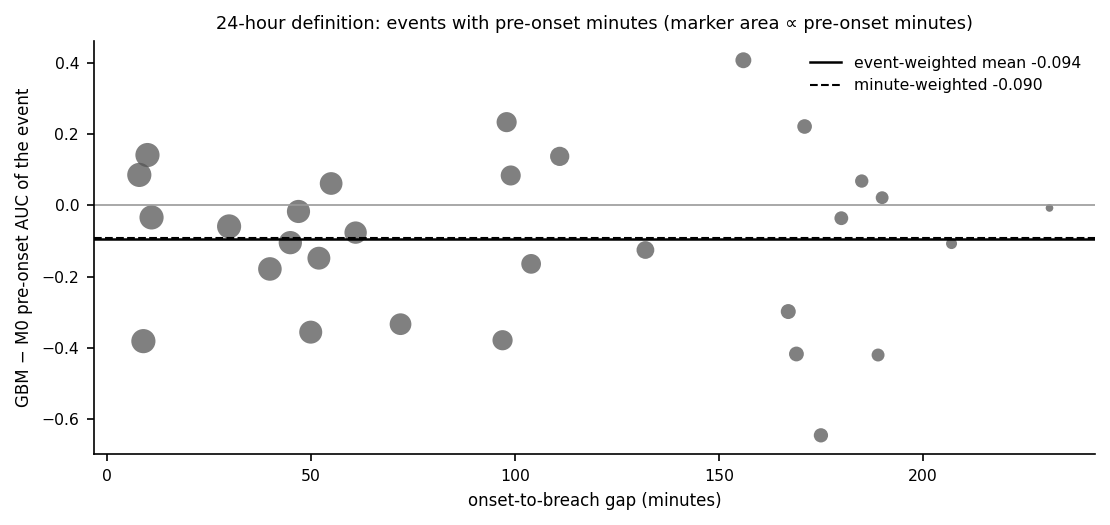

guards: 25 passed of 25. Outputs in /content/drive/MyDrive/btc_lead_cost_results_77months_spot/event_weighted_preonset_v1


In [5]:
p24 = PE[PE.H == H_24].sort_values('onset_to_breach_min')
fig, ax = plt.subplots(figsize=(7.5, 3.6), dpi=150)
ax.scatter(p24.onset_to_breach_min, p24['diff'], s=8 + 0.6 * p24.pre_onset_minutes, color='#555555', alpha=0.75, edgecolor='none')
ax.axhline(0, color='#999999', lw=0.8)
ax.axhline(r1.diff_event_weighted, color='black', lw=1.2, ls='-', label=f'event-weighted mean {r1.diff_event_weighted:+.3f}')
ax.axhline(r1.diff_minute_weighted, color='black', lw=1.0, ls='--', label=f'minute-weighted {r1.diff_minute_weighted:+.3f}')
ax.set_xlabel('onset-to-breach gap (minutes)', fontsize=8); ax.set_ylabel('GBM − M0 pre-onset AUC of the event', fontsize=8)
ax.set_title('24-hour definition: events with pre-onset minutes (marker area ∝ pre-onset minutes)', fontsize=8.5)
ax.tick_params(labelsize=7.5); ax.legend(fontsize=7.5, frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(OUT / 'fig_event_weighted_24h.png'); fig.savefig(OUT / 'fig_event_weighted_24h.pdf'); plt.show()


def _j(o):
    if isinstance(o, (np.floating, np.integer)):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    return str(o)


summary = dict(spec_sha256=SPEC_SHA, run_time=str(pd.Timestamp.now(tz='UTC').floor('s')), status=SPEC['status'],
               mock_bypass_used=bool(any(g['bypassed_in_mock'] for g in GUARDS)), guards=GUARDS, readings=READ,
               outputs=sorted(p.name for p in OUT.iterdir() if p.is_file()) + ['45_SUMMARY.json'])
(OUT / '45_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=_j))
print(f'guards: {sum(g["passed"] is True for g in GUARDS)} passed of {len(GUARDS)}' + (' (guard bypass used)' if summary['mock_bypass_used'] else '') + '. Outputs in', OUT)

## Interpretation
I take R1 as the main reading (in the cell output and under `readings` in `45_SUMMARY.json`). `2_event_weighted.csv` holds the 4-hour and 24-hour event-weighted pre-onset AUCs (including within-regime), the per-minute values and both intervals. `3_per_event_preonset.csv` lists, for each event with pre-onset minutes, its number of pre-onset minutes, minute weight, M0 and GBM event AUCs, their difference and its contribution to the "per-minute − event-weighted" difference (times only, no prices). Because the per-minute value is Σ (minute weight × event AUC difference) and the event-weighted value is the mean of the event AUC differences, their difference equals the sum of the contribution column exactly.